# Numerical Computation — Problem Sheet 2
## Complete worked solutions, Python implementations, and quiz preparation

**TU Wien · Winter Semester 2026/27 · Discussion: 20 October 2026**  
**Source:** *Numerical Computation — Problem Sheet 2* (Faustmann, Bringmann, Marinello); lecture notes, Chapter 1, Sections 1.1–1.6.  
**Language:** English · **Software:** Python 3 with NumPy and Matplotlib.

### How to use this notebook

Every exercise is organized in the same order:

1. **Problem statement** — a faithful, clearly formatted restatement of the sheet.
2. **Mathematical solution** — all essential derivations, including hand calculations.
3. **Python implementation** — executable and independently testable (when requested).
4. **Analysis and oral presentation notes** — interpretation, mathematical reasoning, and points to explain to the tutor.

**The quiz preparation is deliberately placed *after* every solution.** It consists of two separate sections: one covering the concepts tested on Sheet 1, the second covering Sheet 2 and lecture notes Sections 1.1–1.6.

> **Two source clarifications.** Exercise 2.2 refers to “Theorem 1.17” as the interpolation-error formula. In the provided lecture notes, the **general pointwise interpolation-error formula is Theorem 1.15**; Theorem 1.17 is an extrapolation-convergence statement derived from it. Exercise 2.4 suggests using the Neville scheme “from Ex. 2.2”; in this sheet, the Neville implementation is **Exercise 2.3(a)**. These appear to be cross-reference inconsistencies in the sheet, not different mathematical definitions.

## 0. Imports and notebook conventions

We distinguish **knots** $x_i$, **data values** $f_i=f(x_i)$ and **evaluation points** $t$. This avoids confusing the variable used to describe a polynomial with a numerical point at which we evaluate it.

We use floating-point Python implementations for plots and experiments. Exact fractions are retained in hand calculations whenever practical.

In [1]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=12, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4.8), "axes.grid": True})
print("NumPy:", np.__version__)

NumPy: 2.3.5


---
# Exercise 2.1 — Newton interpolation, divided differences, and Horner's scheme

## 2.1 — Problem statement

Consider

$$f(x)=\frac{1}{1+x}, \qquad x\in[0,4],$$

with interpolation knots $x_0=0$, $x_1=1$, $x_2=2$.

**(a)** Compute the divided differences $f[x_i]$, $f[x_0,x_1]$, $f[x_1,x_2]$, and $f[x_0,x_1,x_2]$. Construct the quadratic interpolating polynomial in **Newton form**. Add the point $(4,f(4))$ and update the polynomial to obtain a cubic interpolant $p_3$ in Newton form.

**(b)** Rewrite $p_3$ in nested form and use **Horner's scheme** to compute $p_3(3)$. Determine $|f(3)-p_3(3)|$.

**(c)** Implement a Python function to compute Newton coefficients from knot and data vectors, and another to evaluate the polynomial on a vector of evaluation points via the generalized Horner scheme. Check the results from (a)–(b). Plot $f$ and $p_3$ over $[0,4]$ and approximate $\|f-p_3\|_{\infty,[0,4]}$ using **1001 equally spaced points**.

## 2.1 — Mathematical solution, part (a)

The data values are

$$
\begin{array}{c|c|c}
i & x_i & f[x_i]=f(x_i)\\\hline
0&0&1\\
1&1&\frac12\\
2&2&\frac13\\
3&4&\frac15
\end{array}
$$

For distinct knots, **divided differences** are defined recursively by

$$
f[x_i]=f(x_i),\qquad
f[x_i,\ldots,x_{i+k}]
=\frac{f[x_{i+1},\ldots,x_{i+k}]-f[x_i,\ldots,x_{i+k-1}]}{x_{i+k}-x_i}.
$$

First-order divided differences for the original three knots:

$$
\begin{aligned}
f[x_0,x_1]&=\frac{\frac12-1}{1-0}=-\frac12,\\
f[x_1,x_2]&=\frac{\frac13-\frac12}{2-1}=-\frac16.
\end{aligned}
$$

The second-order divided difference is

$$f[x_0,x_1,x_2]=\frac{-\frac16-\left(-\frac12\right)}{2-0}=\frac16.$$

Consequently, **the quadratic Newton polynomial** is

$$\boxed{p_2(t)=1-\frac12(t-0)+\frac16(t-0)(t-1).}$$

**Update with the knot $x_3=4$.** Rather than recomputing everything, calculate the additional differences:

$$
\begin{aligned}
f[x_2,x_3]&=\frac{\frac15-\frac13}{4-2}=-\frac1{15},\\
f[x_1,x_2,x_3]&=\frac{-\frac1{15}-\left(-\frac16\right)}{4-1}=\frac1{30},\\
f[x_0,x_1,x_2,x_3]&=\frac{\frac1{30}-\frac16}{4-0}=-\frac1{30}.
\end{aligned}
$$

The new coefficient is $d_3=-1/30$; all the earlier Newton coefficients remain unchanged:

$$\boxed{
p_3(t)=1-\frac12t+\frac16t(t-1)-\frac1{30}t(t-1)(t-2).
}$$

The entire divided-difference table (blank entries are not needed) is

| Knot $x_i$ | $f[x_i]$ | First differences | Second differences | Third differences |
|---:|---:|---:|---:|---:|
| $0$ | $1$ | $-1/2$ | $1/6$ | $-1/30$ |
| $1$ | $1/2$ | $-1/6$ | $1/30$ | — |
| $2$ | $1/3$ | $-1/15$ | — | — |
| $4$ | $1/5$ | — | — | — |

The Newton coefficients are the **first row**: $(d_0,d_1,d_2,d_3)=(1,-1/2,1/6,-1/30)$.

## 2.1 — Mathematical solution, part (b): generalized Horner scheme

Rewrite the cubic polynomial in **nested Newton–Horner form**:

$$
\boxed{p_3(t)=1+t\left[-\frac12+(t-1)\left(\frac16-\frac{t-2}{30}\right)\right].}
$$

Horner evaluation at $t=3$ proceeds from the **last coefficient backwards**:

$$
\begin{array}{rl}
y_3&=d_3=-\frac1{30},\\[3pt]
y_2&=d_2+(3-x_2)y_3=\frac16-\frac1{30}=\frac2{15},\\[3pt]
y_1&=d_1+(3-x_1)y_2=-\frac12+2\cdot\frac2{15}=-\frac7{30},\\[3pt]
y_0&=d_0+(3-x_0)y_1=1+3\left(-\frac7{30}\right)=\frac3{10}.
\end{array}
$$

Therefore,

$$\boxed{p_3(3)=0.3},\qquad f(3)=\frac14=0.25,$$

and the **absolute interpolation error** is

$$\boxed{|f(3)-p_3(3)|=\left|\frac14-\frac3{10}\right|=\frac1{20}=0.05.}$$

For checking purposes, the same cubic expressed in the usual monomial basis is

$$p_3(t)=1-\frac{11}{15}t+\frac4{15}t^2-\frac1{30}t^3.$$

However, there is **no need to expand Newton form** in order to evaluate it efficiently.

## 2.1 — Python implementation, part (c)

The algorithms below use only NumPy and implement the formulas in the lecture notes: divided differences in $O(n^2)$ operations and **one Horner evaluation** in $O(n)$ operations after the coefficients are known. A single function evaluates a scalar or any NumPy-compatible collection of points.

In [2]:
def newton_coefficients(knots, values):
    """Return the Newton divided-difference coefficients d_0,...,d_n."""
    x = np.asarray(knots, dtype=float)
    f = np.asarray(values, dtype=float)
    if x.ndim != 1 or f.ndim != 1 or len(x) != len(f):
        raise ValueError("knots and values must be one-dimensional and equally long")
    if len(x) == 0 or np.unique(x).size != len(x):
        raise ValueError("at least one knot is needed; all knots must be distinct")

    d = f.copy()
    for order in range(1, len(x)):
        for j in range(len(x) - 1, order - 1, -1):
            d[j] = (d[j] - d[j - 1]) / (x[j] - x[j - order])
    return d


def newton_horner(knots, coefficients, evaluation_points):
    """Evaluate Newton form by Horner at scalar or vector evaluation_points."""
    x = np.asarray(knots, dtype=float)
    d = np.asarray(coefficients, dtype=float)
    if len(x) != len(d):
        raise ValueError("knots and coefficients must have equal length")
    t = np.asarray(evaluation_points, dtype=float)
    result = np.full_like(t, d[-1], dtype=float)
    for j in range(len(d) - 2, -1, -1):
        result = d[j] + (t - x[j]) * result
    return result


f21 = lambda t: 1.0 / (1.0 + np.asarray(t))
x21 = np.array([0.0, 1.0, 2.0, 4.0])
y21 = f21(x21)
d21 = newton_coefficients(x21, y21)

assert np.allclose(d21, [1.0, -0.5, 1/6, -1/30])
assert np.isclose(newton_horner(x21, d21, 3.0), 0.3)
assert np.allclose(newton_horner(x21, d21, x21), y21)

print("Newton coefficients:", d21)
print("p3(3):", float(newton_horner(x21, d21, 3.0)))
print("Absolute error at 3:", float(abs(f21(3.0) - newton_horner(x21, d21, 3.0))))

Newton coefficients: [ 1.             -0.5             0.166666666667 -0.033333333333]
p3(3): 0.30000000000000004
Absolute error at 3: 0.050000000000000044


Sampled maximum error: 0.053771139999245904
Sampled maximizer: 3.244


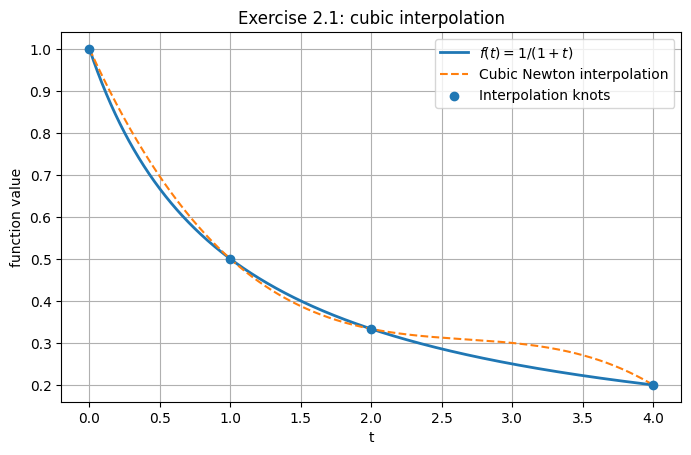

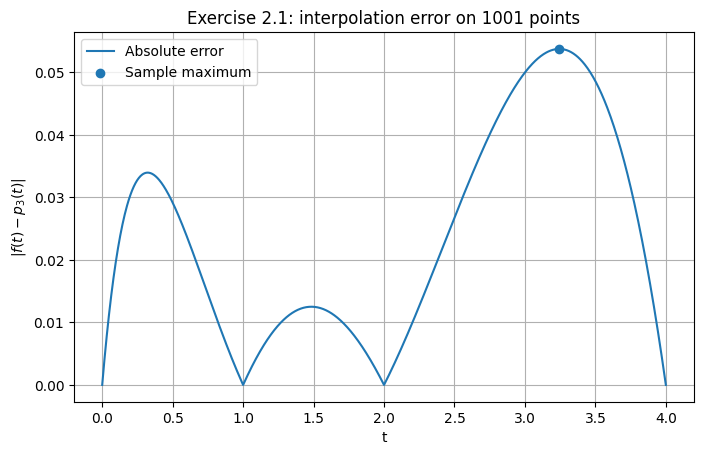

In [3]:
evaluation_grid21 = np.linspace(0.0, 4.0, 1001)
interpolated21 = newton_horner(x21, d21, evaluation_grid21)
errors21 = np.abs(f21(evaluation_grid21) - interpolated21)
max_idx21 = np.argmax(errors21)

print("Sampled maximum error:", errors21[max_idx21])
print("Sampled maximizer:", evaluation_grid21[max_idx21])

plt.figure()
plt.plot(evaluation_grid21, f21(evaluation_grid21), label=r"$f(t)=1/(1+t)$", lw=2)
plt.plot(evaluation_grid21, interpolated21, "--", label="Cubic Newton interpolation")
plt.scatter(x21, y21, label="Interpolation knots", zorder=4)
plt.xlabel("t")
plt.ylabel("function value")
plt.title("Exercise 2.1: cubic interpolation")
plt.legend()
plt.show()

plt.figure()
plt.plot(evaluation_grid21, errors21, label="Absolute error")
plt.scatter([evaluation_grid21[max_idx21]], [errors21[max_idx21]], label="Sample maximum", zorder=4)
plt.xlabel("t")
plt.ylabel(r"$|f(t)-p_3(t)|$")
plt.title("Exercise 2.1: interpolation error on 1001 points")
plt.legend()
plt.show()

## 2.1 — Analysis and presentation notes

- The polynomial agrees **exactly** with the data at $0,1,2,4$, so the interpolation error is zero at all four knots.
- Adding one additional interpolation point is especially convenient in Newton form: **append one new divided difference and one new Newton basis term**; existing coefficients do not change.
- The cubic is not equal to $f$ between the knots. In this case the difference can even be written **exactly**:

  $$\boxed{f(t)-p_3(t)=\frac{t(t-1)(t-2)(t-4)}{30(1+t)}.}$$

  Thus the error vanishes at each knot, but not generally elsewhere.
- On **1001 equally spaced evaluation points**, the maximal absolute error is about **$0.05377$**, attained near **$t=3.244$**. This is a **sampled approximation** to the maximum norm, not a proof of its exact value.
- Complexity: Newton coefficients $O(n^2)$ once; each Horner evaluation $O(n)$. For $M$ evaluation points the total is $O(n^2+Mn)$.

**How to present:** Show the divided-difference table, write the cubic Newton formula, explain the nested Horner evaluation at $t=3$, and point at the error plot. Explicitly distinguish the error at a **single point** ($0.05$) from the sampled **maximum error** (about $0.05377$).

---
# Exercise 2.2 — Quadratic interpolation and error bounds

## 2.2 — Problem statement

Interpolate $f(x)=e^x$ on $[0,2]$ using the points

$$ (0,1), \qquad (1,e),\qquad (2,e^2).$$

Find the **actual error at $x=1.2$**. Using the interpolation-error formula from the lecture notes, derive (i) an **upper bound for $|f(x)-p_2(x)|$** at an arbitrary fixed $x\in[0,2]$, and (ii) an **upper bound for the maximum error** $\|f-p_2\|_{\infty,[0,2]}$.

**Note on the sheet:** It cites Theorem 1.17; the relevant general error identity in the uploaded notes is **Theorem 1.15, Equation (1.15)**. Theorem 1.17 uses that identity to study extrapolation rates.

## 2.2 — Complete mathematical solution

Using Newton's divided differences (the Lagrange form would give the same unique polynomial):

$$
\begin{aligned}
d_0&=1,\\
d_1&=\frac{e-1}{1-0}=e-1,\\
f[1,2]&=e^2-e,\\
d_2&=\frac{(e^2-e)-(e-1)}{2-0}
=\frac{e^2-2e+1}{2}=\frac{(e-1)^2}{2}.
\end{aligned}
$$

Hence the **quadratic interpolant** is

$$\boxed{p_2(x)=1+(e-1)x+\frac{(e-1)^2}{2}\,x(x-1).}$$

### Actual error at $x=1.2$

Substitute $x=1.2$:

$$
\begin{aligned}
p_2(1.2)&=1+1.2(e-1)+0.12(e-1)^2,\\
f(1.2)-p_2(1.2)&=e^{1.2}-\left[1+1.2(e-1)+0.12(e-1)^2\right].
\end{aligned}
$$

Numerically,

$$\boxed{f(1.2)-p_2(1.2)\approx -0.0961203645,}\qquad
\boxed{|f(1.2)-p_2(1.2)|\approx 0.0961203645.}$$

### Pointwise theoretical error bound

The general error formula for interpolation of degree $n$ is

$$f(x)-p_n(x)=\frac{f^{(n+1)}(\xi_x)}{(n+1)!}\prod_{j=0}^{n}(x-x_j),$$

for some $\xi_x$ in the interval containing the nodes and $x$. With $n=2$ and the three knots $0,1,2$:

$$f(x)-p_2(x)=\frac{e^{\xi_x}}{3!}\,x(x-1)(x-2).$$

Since $0\le \xi_x\le2$, we have $e^{\xi_x}\le e^2$. Therefore

$$\boxed{|f(x)-p_2(x)|\le \frac{e^2}{6}\,|x(x-1)(x-2)|,\quad x\in[0,2].}$$

In particular, at $x=1.2$,

$$|x(x-1)(x-2)|=|1.2\cdot0.2\cdot(-0.8)|=0.192,$$

so the **pointwise upper bound** is

$$\boxed{|f(1.2)-p_2(1.2)|\le 0.032e^2\approx 0.2364497952.}$$

This bound is correct but conservative: the actual error is about $0.09612$.

### Upper bound for the maximum error

We need to maximize $|x(x-1)(x-2)|$ on $[0,2]$. Define

$$g(x)=x(x-1)(x-2)=x^3-3x^2+2x.$$

The derivative is

$$g'(x)=3x^2-6x+2=0\iff x=1\pm\frac1{\sqrt3}.$$

At both points,

$$|g(x)|=\frac{2}{3\sqrt3};$$

at $x=0,1,2$, its absolute value is zero. Therefore

$$
\begin{aligned}
\|f-p_2\|_{\infty,[0,2]}
&\le\frac{e^2}{6}\max_{x\in[0,2]}|x(x-1)(x-2)|\\
&=\frac{e^2}{6}\cdot\frac{2}{3\sqrt3}
=\boxed{\frac{e^2}{9\sqrt3}}.
\end{aligned}
$$

Thus the **uniform error bound** is about **$0.47400817$**. It holds for *all* points in the interval, not just at $x=1.2$.

## 2.2 — Optional numerical verification (not required by the sheet)

p2(1.2)                 = 3.416237287192
Actual absolute error    = 0.096120364456
Pointwise upper bound    = 0.236449795166
Uniform theoretical bound = 0.474008169753


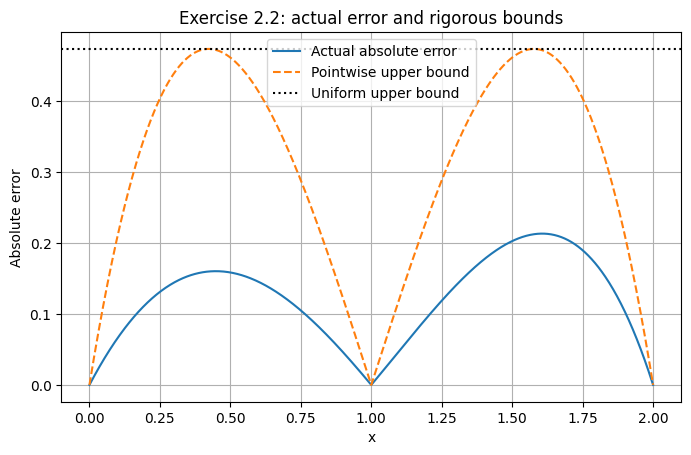

In [4]:
def p22(x):
    t = np.asarray(x, dtype=float)
    return 1 + (np.e - 1) * t + 0.5 * (np.e - 1)**2 * t * (t - 1)

point22 = 1.2
actual22 = abs(np.exp(point22) - p22(point22))
bound_point22 = np.e**2 / 6 * abs(point22 * (point22 - 1) * (point22 - 2))
bound_max22 = np.e**2 / (9 * np.sqrt(3))

print(f"p2(1.2)                 = {float(p22(point22)):.12f}")
print(f"Actual absolute error    = {float(actual22):.12f}")
print(f"Pointwise upper bound    = {bound_point22:.12f}")
print(f"Uniform theoretical bound = {bound_max22:.12f}")
assert actual22 <= bound_point22 <= bound_max22

x22 = np.linspace(0, 2, 1001)
plt.figure()
plt.plot(x22, np.abs(np.exp(x22) - p22(x22)), label="Actual absolute error")
plt.plot(x22, np.e**2/6 * np.abs(x22*(x22-1)*(x22-2)), "--", label="Pointwise upper bound")
plt.axhline(bound_max22, linestyle=":", color="black", label="Uniform upper bound")
plt.xlabel("x")
plt.ylabel("Absolute error")
plt.title("Exercise 2.2: actual error and rigorous bounds")
plt.legend()
plt.show()

## 2.2 — Analysis and presentation notes

- The **actual interpolation error** is a value you obtain from the computed polynomial; a **theoretical error bound** is a mathematically guaranteed upper estimate.
- The term $\prod_{j=0}^n(x-x_j)$ is zero at each interpolation knot. This explains why interpolation has zero error at the original data points.
- The derivative order in the error formula is **one higher than the interpolation degree**. A quadratic interpolant ($n=2$) requires $f^{(3)}$ and the factor $3!$.
- The maximum error bound requires **two separate maximizations/estimates**: bound $|f^{(3)}|$ and bound the magnitude of the knot polynomial $|\omega_3|$.
- This exercise has **no required programming part**.

**How to present:** Derive $p_2$, calculate the numerical error, write the pointwise error identity and explain why $e^\xi\le e^2$. For the interval-wide estimate, differentiate the cubic knot product and give the final bound $e^2/(9\sqrt3)$.

---
# Exercise 2.3 — Neville's scheme, derivative extrapolation, and convergence

## 2.3 — Problem statement

**(a)** Implement the **Neville scheme** in Python. Inputs are knot vector $x$ and data vector $f$, both of length $n+1$, together with a point $t$ at which the interpolation polynomial is evaluated. The output is a **$(n+1)\times(n+1)$ array** $N$, holding all meaningful columns of the Neville scheme.

**(b)** Let

$$D_{\mathrm{sym}}(h)=\frac{f(x_0+h)-f(x_0-h)}{2h}$$

be the **symmetric difference quotient**. For $f(x)=\tan x$, $x_0=\pi/4$ and

$$h_i=2^{-i},\quad i=0,\ldots,10,$$

extrapolate the derivative at $h=0$ using the **first four columns** of the Neville scheme. Recall that

$$f'(\pi/4)=\frac{1}{\cos^2(\pi/4)}=2.$$

Create a **log-log plot** of the absolute error versus $h$ for all four columns; include lines proportional to $h^2$, $h^3$, and $h^4$. Explain the convergence orders actually observed.

## 2.3 — Mathematical solution, part (a): Neville recurrence

Denote by $p_{j,m}$ the polynomial of degree at most $m$ interpolating at the **consecutive knots** $x_j,\ldots,x_{j+m}$. Its value at the evaluation point $t$ is computed by the recursive formula from the notes (Theorem 1.4):

$$\boxed{
p_{j,0}(t)=f_j,\qquad
p_{j,m}(t)=\frac{(t-x_j)p_{j+1,m-1}(t)-(t-x_{j+m})p_{j,m-1}(t)}{x_{j+m}-x_j}.
}$$

Define $N_{j,m}=p_{j,m}(t)$. The zeroth column stores $f_0,\ldots,f_n$, then each column is built from the **two appropriate neighboring entries in the previous column**. The final interpolation value is

$$\boxed{p_n(t)=N_{0,n}.}$$

The array is triangular in the sense that $N_{j,m}$ is defined only if $0\le j\le n-m$; undefined positions can be stored as `np.nan`.

**Why two neighboring values?** Each of the two polynomials in the recurrence interpolates on $m$ points. Their weighted combination satisfies the interpolation conditions on the **union of $m+1$ knots**.

**Complexity:** $1+2+\cdots+n=n(n+1)/2$ recurrence evaluations, so one full Neville table costs $O(n^2)$ arithmetic operations and the full table needs $O(n^2)$ storage.

## 2.3 — Python implementation, part (a)

In [5]:
def neville_table(knots, values, evaluation_point):
    """Return Neville table N[j, m] = p_{j,m}(evaluation_point)."""
    x = np.asarray(knots, dtype=float)
    f = np.asarray(values, dtype=float)
    if x.ndim != 1 or f.ndim != 1 or len(x) != len(f):
        raise ValueError("knots and values must be equal-length 1D arrays")
    if len(x) == 0 or np.unique(x).size != len(x):
        raise ValueError("at least one knot is needed; all knots must be distinct")

    n = len(x) - 1
    N = np.full((n + 1, n + 1), np.nan, dtype=float)
    N[:, 0] = f
    t = float(evaluation_point)

    for m in range(1, n + 1):
        for j in range(n + 1 - m):
            N[j, m] = (
                (t - x[j]) * N[j + 1, m - 1]
                - (t - x[j + m]) * N[j, m - 1]
            ) / (x[j + m] - x[j])
    return N


# Check against the lecture's example with (0,1), (1,3), (3,2), evaluated at t=2.
N_check = neville_table([0, 1, 3], [1, 3, 2], 2.0)
assert np.isclose(N_check[0, 2], 10/3)
print("Check Neville value p(2):", N_check[0, 2])
print("Neville table (undefined entries are nan):\n", N_check)

Check Neville value p(2): 3.3333333333333335
Neville table (undefined entries are nan):
 [[1.             5.             3.333333333333]
 [3.             2.5                       nan]
 [2.                        nan            nan]]


## 2.3 — Mathematical solution, part (b): why the orders are $2,2,4,4$

We apply the scheme to the **new function** $D_{\mathrm{sym}}(h)$, interpolating the pairs $(h_i,D_{\mathrm{sym}}(h_i))$ and **evaluating the interpolation polynomial at $t=0$**. Note that $t=0$ is *outside* the positive knot interval: we are **extrapolating**.

Because $f(x)=\tan x$ and $x_0=\pi/4$, the symmetric quotient simplifies by the tangent addition formula:

$$
\begin{aligned}
D_{\mathrm{sym}}(h)
&=\frac{\tan(\pi/4+h)-\tan(\pi/4-h)}{2h}\\
&=\frac{\tan(2h)}{h},
\end{aligned}
$$

where the expression is defined. Its limit at zero is $2$. Near $h=0$, expand with the Taylor series of the tangent:

$$\tan z=z+\frac{z^3}{3}+\frac{2z^5}{15}+O(z^7).$$

Therefore

$$\boxed{D_{\mathrm{sym}}(h)=2+\frac83h^2+\frac{64}{15}h^4+O(h^6).}$$

**Crucial observation:** The symmetric difference quotient is an **even function of $h$**, hence its local expansion contains **even powers only**, not an $h$ or $h^3$ term.

Let the first column correspond to degree $m=0$, the second to $m=1$, and so on:

- **Column 1 ($m=0$):** $D_{\mathrm{sym}}(h)-2=O(h^2)$.
- **Column 2 ($m=1$):** linear extrapolation cancels the linear term, but there is **no linear term to cancel**. The leading $h^2$ contribution remains, so the error is $O(h^2)$.
- **Column 3 ($m=2$):** quadratic interpolation reproduces the $h^2$ term exactly, and the next nonzero term is $h^4$. Hence the error is $O(h^4)$.
- **Column 4 ($m=3$):** cubic interpolation cancels a possible $h^3$ contribution, but that term is already zero. Therefore the leading error remains $O(h^4)$.

Thus the **observed asymptotic orders** should be

$$\boxed{\text{columns 1--4: } O(h^2),\quad O(h^2),\quad O(h^4),\quad O(h^4).}$$

**Important subtlety for this particular problem:** The formula for $\tan(\pi/4+h)$ has a pole at $h=\pi/4$. Our largest prescribed knot $h_0=1$ is **on the other side of that pole**. The value at $h=1$ is finite, but early rows that involve it are not in the same smooth branch as the limit $h\to0$. The asymptotic rates must therefore be judged from the **small-$h$ rows**, not from the largest steps.

## 2.3 — Python implementation, part (b): full extrapolation table and log-log plot

In [6]:
nmax23 = 10
h23 = 2.0 ** (-np.arange(nmax23 + 1, dtype=float))
x0_23 = np.pi / 4

# Directly use the difference quotient in the statement.
Dsym23 = (np.tan(x0_23 + h23) - np.tan(x0_23 - h23)) / (2 * h23)
N23 = neville_table(h23, Dsym23, 0.0)
errors23 = np.abs(N23[:, :4] - 2.0)

print("  i      h_i       column 1      column 2      column 3      column 4")
for i in range(len(h23)):
    entries = [f"{N23[i, m]: .8f}" if np.isfinite(N23[i, m]) else "     ---   " for m in range(4)]
    print(f"{i:3d} {h23[i]:10.6f}  " + "   ".join(entries))

  i      h_i       column 1      column 2      column 3      column 4
  0   1.000000  -2.18503986    8.41467076   -1.13075096    2.57884581
  1   0.500000   3.11481545    1.25560447    2.11514622    1.98837158
  2   0.250000   2.18520996    1.90026078    2.00421841    1.99966716
  3   0.125000   2.04273537    1.97822900    2.00023607    1.99998270
  4   0.062500   2.01048219    1.99473430    2.00001437    1.99999897
  5   0.031250   2.00260824    1.99869435    2.00000089    1.99999994
  6   0.015625   2.00065130    1.99967426    2.00000006    2.00000000
  7   0.007812   2.00016278    1.99991861    2.00000000    2.00000000
  8   0.003906   2.00004069    1.99997965    2.00000000        ---   
  9   0.001953   2.00001017    1.99999491        ---           ---   
 10   0.000977   2.00000254        ---           ---           ---   


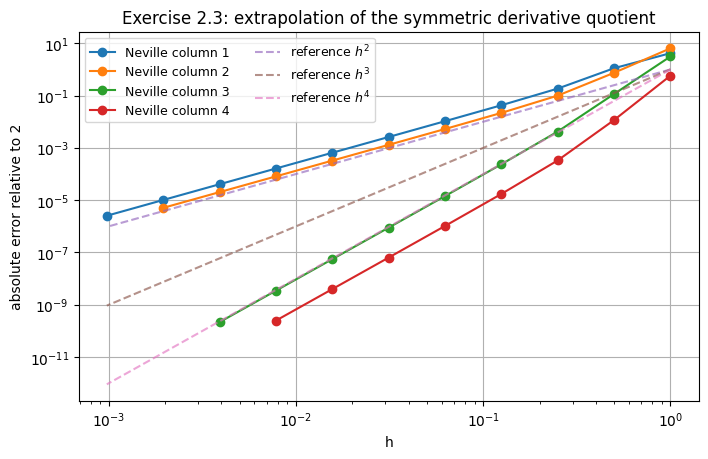

Estimated orders using consecutive rows at i = 5, 6, 7:
Column 1: [2.0017 2.0004 2.0001], average = 2.001
Column 2: [2.003  2.0007 2.0002], average = 2.001
Column 3: [4.0024 4.0006 4.0001], average = 4.001
Column 4: [4.0042 4.001 ], average = 4.003


In [7]:
plt.figure()
for col in range(4):
    valid = np.isfinite(errors23[:, col]) & (errors23[:, col] > 0)
    plt.loglog(h23[valid], errors23[valid, col], "o-", label=f"Neville column {col + 1}")

# Lines requested in the exercise: h^2, h^3, h^4.
for power in (2, 3, 4):
    plt.loglog(h23, h23**power, "--", alpha=0.65, label=fr"reference $h^{power}$")

plt.xlabel("h")
plt.ylabel("absolute error relative to 2")
plt.title("Exercise 2.3: extrapolation of the symmetric derivative quotient")
plt.legend(ncol=2, fontsize=9)
plt.show()

# Estimate observed log-log slopes using small h (but not the very last, noisy points).
print("Estimated orders using consecutive rows at i = 5, 6, 7:")
for col in range(4):
    i = np.arange(5, 8)
    valid = np.isfinite(errors23[i+1, col]) & (errors23[i, col] > 0) & (errors23[i+1, col] > 0)
    slopes = np.log(errors23[i[valid] + 1, col] / errors23[i[valid], col]) / np.log(0.5)
    print(f"Column {col+1}: {np.round(slopes, 4)}, average = {np.mean(slopes):.3f}")

# Sanity checks: the orders must be close to 2, 2, 4, 4 in the asymptotic regime.
for col, expected in enumerate((2, 2, 4, 4)):
    i = 6
    slope = np.log(errors23[i + 1, col]/errors23[i, col]) / np.log(0.5)
    assert abs(slope - expected) < 0.1

## 2.3 — Analysis and presentation notes

- **Interpolation** estimates a value inside the knot interval; **extrapolation** estimates a value outside it. Here every $h_i$ is positive but the desired argument is $h=0$.
- The Neville table is calculated at the **same evaluation point $t=0$ for all entries**. Its first column contains the sampled symmetric difference quotients.
- In a log-log plot, if $E(h)\approx Ch^p$, the graph approaches a straight line with **slope $p$**. Halving $h$ then decreases the error by approximately $2^p$: factor $4$ for $p=2$, factor $16$ for $p=4$.
- The reference line $h^3$ is requested to facilitate comparison; it **does not imply** that any actual Neville column has order three.
- For very small errors, **floating-point cancellation and rounding** can eventually spoil the ideal slope. The mathematical claims describe asymptotic truncation error before roundoff dominates.

**How to present:** Write the Neville recurrence, explain why evaluating at $0$ is extrapolation, show that the symmetric quotient has only even Taylor powers, and **justify the unexpected repeated rates $2,2,4,4$**. Mention the pole at $h=\pi/4$ if someone asks why the first points do not follow the trend.

---
# Exercise 2.4 — Best approximation, Taylor series, and Chebyshev interpolation

## 2.4 — Problem statement

For

$$f(x)=\frac{1}{4-x^2},\quad x\in[-1,1],$$

**(i)** Provide an upper estimate for the **best polynomial approximation error** of maximal degree $n$,

$$E_n^{\mathrm{best}}=\min_{q\in\mathcal P_n}\|f-q\|_{\infty,[-1,1]},$$

by selecting the Taylor polynomial about a suitable expansion point.

**(ii)** For $n=1,\ldots,20$, compute the **degree-$n$ Chebyshev interpolant** $I_n^{\mathrm{Cheb}}f$. Approximately determine its maximum error from **100 uniformly spaced evaluation points** on $[-1,1]$ and plot error versus $n$ using `semilogy`.

**(iii)** On the same plot show the error of the **degree-$2n$ Taylor polynomial** $T_{2n}f$ about $x=0$. Compare the quality of these two approximations.

The sheet says one may reuse the Neville scheme from “Ex. 2.2”; in this sheet, it is implemented in **2.3(a)**.

## 2.4 — Complete mathematical solution, part (i): an explicit upper bound

The function is even, so the natural Taylor expansion point is **$x_0=0$**. For $|x|\le1$, the geometric series yields

$$
\begin{aligned}
f(x)&=\frac1{4-x^2}
=\frac14\cdot\frac1{1-x^2/4}\\
&=\frac14\sum_{k=0}^{\infty}\left(\frac{x^2}{4}\right)^k
=\frac14+\frac{x^2}{16}+\frac{x^4}{64}+\cdots.
\end{aligned}
$$

For a **maximal allowed polynomial degree $n$**, set $m=\lfloor n/2\rfloor$. The admissible Taylor polynomial is

$$\boxed{T_{2m}f(x)=\sum_{k=0}^{m}\frac{x^{2k}}{4^{k+1}}\in\mathcal P_n.}$$

There are no odd powers. Therefore, for odd $n$, the degree-$n$ Taylor truncation is the same as for $n-1$.

Subtract the geometric partial sum:

$$
\begin{aligned}
f(x)-T_{2m}f(x)
&=\frac14\cdot\frac{(x^2/4)^{m+1}}{1-x^2/4}\\
&=\boxed{\frac{x^{2m+2}}{4^{m+1}(4-x^2)}}.
\end{aligned}
$$

On $[-1,1]$, the remainder is nonnegative, increases with $|x|$, and is largest at $x=\pm1$. Thus this particular Taylor polynomial has the **exact maximum error**

$$\boxed{\|f-T_{2m}f\|_{\infty,[-1,1]}=\frac1{3\cdot4^{m+1}}.}$$

Because the **best** polynomial cannot be worse than an explicitly chosen polynomial,

$$
\boxed{
\min_{q\in\mathcal P_n}\|f-q\|_{\infty,[-1,1]}
\le\frac1{3\cdot4^{\lfloor n/2\rfloor+1}}.
}
$$

**This is an upper bound, not an equality for the best possible polynomial.** Proving equality would require showing that no other polynomial of degree at most $n$ performs better, which we have not done.

## 2.4 — Complete mathematical solution, parts (ii)–(iii)

The **Chebyshev points** on $[-1,1]$ for a polynomial of degree at most $n$ are

$$\boxed{x_i^{\mathrm{Cheb}}=\cos\left(\frac{(2i+1)\pi}{2n+2}\right),\quad i=0,\ldots,n.}$$

There are $n+1$ nodes. They are **more densely distributed near the endpoints** than uniform knots. Construct the unique interpolating polynomial through $(x_i^{\mathrm{Cheb}}, f(x_i^{\mathrm{Cheb}}))$.

To estimate the maximum error as requested, define the 100-point grid $t_j=-1+2j/99$ and use

$$\widehat E_n^{\mathrm{Cheb}}=
\max_{j=0,\ldots,99}|f(t_j)-(I_n^{\mathrm{Cheb}}f)(t_j)|.$$

For the Taylor polynomial **of degree $2n$**, the exact error derived above (now put $m=n$) is

$$\boxed{\|f-T_{2n}f\|_{\infty,[-1,1]}=\frac1{3\cdot4^{n+1}}.}$$

We can therefore plot one approximately sampled maximum norm and one exact maximum norm. The sheet requests these different degrees; **this is not a comparison at equal polynomial degree**. The Chebyshev approximant has degree $n$, whereas the Taylor approximant has degree $2n$.

## 2.4 — Python implementation: reuse Neville's scheme

This code uses the `neville_table` function already implemented in Exercise 2.3. No direct polynomial fitting or undocumented library interpolation routine is necessary.

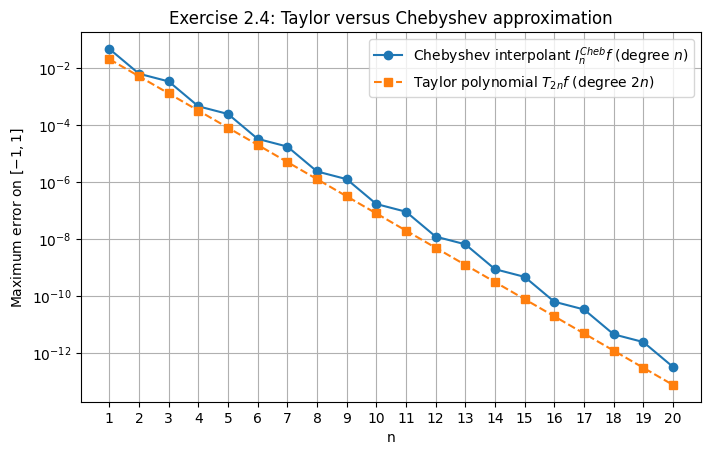

 n   sampled Chebyshev error       exact Taylor(2n) error
 1    4.76190476190e-02             2.08333333333e-02
 2    6.41025641026e-03             5.20833333333e-03
 3    3.43642611684e-03             1.30208333333e-03
 4    4.60405156538e-04             3.25520833333e-04
 5    2.46730816679e-04             8.13802083333e-05
 6    3.30556657412e-05             2.03450520833e-05
 7    1.77144780429e-05             5.08626302083e-06
 8    2.37329004449e-06             1.27156575521e-06
 9    1.27184230170e-06             3.17891438802e-07
10    1.70394558796e-07             7.94728597005e-08
11    9.13141688375e-08             1.98682149251e-08
12    1.22337791009e-08             4.96705373128e-09
13    6.55606252620e-09             1.24176343282e-09
14    8.78345840505e-10             3.10440858205e-10
15    4.70704142330e-10             7.76102145513e-11
16    6.30626662002e-11             1.94025536378e-11
17    3.37950778473e-11             4.85063840946e-12
18    4.52776705018e-12 

In [8]:
def chebyshev_points(n):
    """Return n+1 Chebyshev roots (interpolation knots) on [-1,1]."""
    i = np.arange(n + 1)
    return np.cos((2 * i + 1) * np.pi / (2 * n + 2))


def f24(x):
    x = np.asarray(x, dtype=float)
    return 1.0 / (4.0 - x**2)


def taylor24(x, max_degree):
    """Taylor polynomial of f24 at zero, truncated to maximal degree max_degree."""
    x = np.asarray(x, dtype=float)
    m = max_degree // 2
    result = np.zeros_like(x, dtype=float)
    # Horner in z=x^2/4 for the geometric partial sum.
    z = x**2 / 4
    for _ in range(m, -1, -1):
        result = 0.25 + z * result
    return result


n_values24 = np.arange(1, 21)
sample24 = np.linspace(-1, 1, 100)  # Exactly 100 evaluation points, as prescribed.
chebyshev_errors24 = []
taylor_errors24 = []

for n in n_values24:
    nodes = chebyshev_points(int(n))
    values = f24(nodes)
    interp = np.array([neville_table(nodes, values, t)[0, int(n)] for t in sample24])
    chebyshev_errors24.append(np.max(np.abs(f24(sample24) - interp)))

    # Exact uniform Taylor error; also checked against the 100-point numerical evaluation.
    exact_taylor_error = 1.0 / (3.0 * 4.0**(int(n) + 1))
    taylor_errors24.append(exact_taylor_error)
    sampled_taylor_error = np.max(np.abs(f24(sample24) - taylor24(sample24, 2 * int(n))))
    if n <= 12:  # At very high n, values approach machine precision.
        assert np.isclose(sampled_taylor_error, exact_taylor_error, rtol=1e-4, atol=1e-14)

chebyshev_errors24 = np.asarray(chebyshev_errors24)
taylor_errors24 = np.asarray(taylor_errors24)

plt.figure()
plt.semilogy(n_values24, chebyshev_errors24, "o-", label=r"Chebyshev interpolant $I_n^{Cheb} f$ (degree $n$)")
plt.semilogy(n_values24, taylor_errors24, "s--", label=r"Taylor polynomial $T_{2n} f$ (degree $2n$)")
plt.xlabel("n")
plt.ylabel(r"Maximum error on $[-1,1]$")
plt.title("Exercise 2.4: Taylor versus Chebyshev approximation")
plt.xticks(n_values24)
plt.legend()
plt.show()

print(" n   sampled Chebyshev error       exact Taylor(2n) error")
for n, ec, et in zip(n_values24, chebyshev_errors24, taylor_errors24):
    print(f"{n:2d}   {ec: .11e}            {et: .11e}")

## 2.4 — Analysis and presentation notes

- **Best approximation** means minimizing the maximum error over **all** polynomials in $\mathcal P_n$. Constructing any particular polynomial yields an **upper bound** for that minimum.
- Since $f$ is even, the Taylor series at zero contains **even powers only**. This simplifies both the formula and the remainder.
- **Chebyshev points** are chosen to control the size of the interpolation node product and thereby improve interpolation performance, especially at high degrees. They do not mean “ordinary equally spaced nodes.”
- The numerical plot should show **rapid, approximately exponential reduction of the errors**. A straight decreasing line in a **semilogy** plot is typical of a geometric/exponential decay $C\rho^n$ with $0<\rho<1$.
- **For this specified comparison**, the degree-$2n$ Taylor polynomial is more accurate than the degree-$n$ Chebyshev interpolant for the investigated values, but it also has **twice the nominal polynomial degree**. You cannot conclude that Taylor approximation always beats Chebyshev interpolation at equal degree.
- At sufficiently high $n$, errors may approach $10^{-15}$ in double precision, at which point numerical roundoff can obscure the ideal asymptotic convergence.

**How to present:** Derive the geometric Taylor series and exact remainder; explain why that remainder bounds the best-approximation error. Give the Chebyshev knot formula, describe the 100-point sampled error, and explicitly flag that the compared degrees differ: $n$ versus $2n$.

---
# Exercise 2.5 — Harmonic series, fitted asymptotic coefficients, and runtime

## 2.5 — Problem statement

For large positive integers $N$, efficiently approximate the **harmonic sum**

$$S(N)=\sum_{k=1}^{N}\frac1k.$$

The sheet provides the asymptotic form

$$S(N)=\ln N+a_0+\frac{a_1}{N}+\frac{a_2}{N^2}+\cdots.$$

**(i)** Write a program for $S(N)$.

**(ii)** Neglect the terms represented by $\cdots$, set up the **$3\times3$ linear system** from $N=10,100,1000$, and solve for $a_0,a_1,a_2$ using `numpy.linalg.solve`.

**(iii)** Determine the approximation errors for $N=10^6$ and $N=10^8$.

**(iv)** Compare evaluation times of the fitted approximation and direct harmonic summation for $N=10^8$ and $N=10^9$ on your computer.

## 2.5 — Mathematical solution: fit the coefficients

If we truncate the series after $a_2/N^2$, define

$$\boxed{A(N)=\ln N+a_0+\frac{a_1}{N}+\frac{a_2}{N^2}.}$$

Impose $A(N_j)=S(N_j)$ for $N_0=10$, $N_1=100$, $N_2=1000$. Rearranging yields three **linear equations**:

$$
\begin{aligned}
a_0+\frac{a_1}{10}+\frac{a_2}{100}&=S(10)-\ln10,\\
a_0+\frac{a_1}{100}+\frac{a_2}{10^4}&=S(100)-\ln100,\\
a_0+\frac{a_1}{1000}+\frac{a_2}{10^6}&=S(1000)-\ln1000.
\end{aligned}
$$

In matrix form,

$$
\boxed{
\underbrace{\begin{pmatrix}
1&10^{-1}&10^{-2}\\
1&10^{-2}&10^{-4}\\
1&10^{-3}&10^{-6}
\end{pmatrix}}_{M}
\underbrace{\begin{pmatrix}a_0\\a_1\\a_2\end{pmatrix}}_{a}
=
\underbrace{\begin{pmatrix}S(10)-\ln10\\S(100)-\ln100\\S(1000)-\ln1000\end{pmatrix}}_{b}.
}
$$

We find $a$ by solving **$Ma=b$**. This step is not Newton interpolation; it is fitting the three unknown coefficients of a truncated asymptotic model.

### Why this is fast

The direct sum uses $N$ terms, hence $O(N)$ arithmetic operations. Once $a_0,a_1,a_2$ are available, evaluating $A(N)$ needs a logarithm and only a fixed number of operations: **$O(1)$ cost per evaluation** (under standard arithmetic-cost assumptions).

The leading coefficients of the *true* large-$N$ harmonic expansion are known to be $\gamma\approx0.5772156649$, $1/2$, and $-1/12\approx-0.08333333$. **This known asymptotic expansion is supplementary mathematical context**, not a requirement to solve the sheet: our fitted coefficients come from the three prescribed sample sums, and will be close but not identical to these theoretical values.

## 2.5 — Python implementation: direct sum and fitted asymptotic approximation

We compute direct harmonic sums in **chunks** of bounded size. This allows $N=10^9$ to be evaluated without allocating an array containing a billion numbers (which would require many gigabytes of RAM). Chunking still costs $O(N)$ operations.

In [9]:
def harmonic_sum(N, chunk_size=1_000_000):
    """Compute H_N = sum_{k=1}^N 1/k with a memory-bounded NumPy loop."""
    if not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError("N must be a positive integer")
    total = 0.0
    for start in range(1, N + 1, chunk_size):
        stop = min(N + 1, start + chunk_size)
        integers = np.arange(start, stop, dtype=np.float64)
        total += np.sum(1.0 / integers, dtype=np.float64)
    return float(total)


fit_ns25 = np.array([10, 100, 1000], dtype=int)
fit_sums25 = np.array([harmonic_sum(int(n)) for n in fit_ns25])
M25 = np.column_stack([np.ones(3), 1.0/fit_ns25, 1.0/fit_ns25**2])
b25 = fit_sums25 - np.log(fit_ns25)
a25 = np.linalg.solve(M25, b25)


def harmonic_approximation(N):
    """Approximate S(N) using coefficients fitted at N=10,100,1000."""
    return math.log(N) + a25[0] + a25[1]/N + a25[2]/(N*N)


assert np.allclose(M25 @ a25, b25)
assert np.allclose([harmonic_approximation(int(n)) for n in fit_ns25], fit_sums25)

print("Fitted coefficients from N=10,100,1000:")
for i, a in enumerate(a25):
    print(f"a{i} = {a:.12f}")
print("Known asymptotic coefficients (for context only):")
print(f"gamma = {np.euler_gamma:.12f}, a1=0.5, a2=-1/12={-1/12:.12f}")

Fitted coefficients from N=10,100,1000:
a0 = 0.577215665822
a1 = 0.499998986431
a2 = -0.083240349105
Known asymptotic coefficients (for context only):
gamma = 0.577215664902, a1=0.5, a2=-1/12=-0.083333333333


## 2.5 — Numerical error at $N=10^6$ and $N=10^8$

We directly compute both requested harmonic sums using the same `harmonic_sum` routine. The **signed error** is $A(N)-S(N)$ and the **absolute error** is $|A(N)-S(N)|$. For additional cross-checking (not needed for the sheet), we also use the known high-accuracy expansion

$$S(N)=\ln N+\gamma+\frac1{2N}-\frac1{12N^2}+\frac1{120N^4}+O(N^{-6}),$$

which is exceptionally accurate for $N\ge10^6$. It is used only as an **independent reference**, not to determine the fitted coefficients.

In [10]:
def harmonic_reference_asymptotic(N):
    """High-accuracy independent reference for LARGE N (Euler--Maclaurin)."""
    N = float(N)
    return math.log(N) + np.euler_gamma + 0.5/N - 1/(12*N*N) + 1/(120*N**4)


for n in (10**6, 10**8):
    direct = harmonic_sum(n)
    fitted = harmonic_approximation(n)
    reference = harmonic_reference_asymptotic(n)
    print(f"N = {n:,}")
    print(f"  Direct harmonic sum  = {direct:.15f}")
    print(f"  Fitted approximation = {fitted:.15f}")
    print(f"  Signed error (fit - direct)    = {fitted - direct:.12e}")
    print(f"  Absolute error (fit - direct)  = {abs(fitted - direct):.12e}")
    print(f"  Absolute error (fit - reference) = {abs(fitted - reference):.12e}")
    print()

N = 1,000,000
  Direct harmonic sum  = 14.392726722865726
  Fitted approximation = 14.392726723785302
  Signed error (fit - direct)    = 9.195755268365e-10
  Absolute error (fit - direct)  = 9.195755268365e-10
  Absolute error (fit - reference) = 9.195773031934e-10



N = 100,000,000
  Direct harmonic sum  = 18.997896413853926
  Fitted approximation = 18.997896414774484
  Signed error (fit - direct)    = 9.205578521687e-10
  Absolute error (fit - direct)  = 9.205578521687e-10
  Absolute error (fit - reference) = 9.205827211645e-10



## 2.5 — Runtime experiment for $10^8$ and $10^9$

The time you measure **depends on your CPU, software, and background load**, so the sheet expects numbers **measured on your own computer**, not universal timings from a book. Run the cell below to see both requested sizes.

- `RUN_LARGE_DIRECT_TIMINGS = True` (default) performs the **entire direct sum** for $10^8$ and $10^9$, in bounded-memory chunks. Depending on hardware, $10^9$ may take significant time.
- Change it to `False` if you only want to examine the instantaneous asymptotic-approximation runtimes or avoid the large workload.
- The approximation is so fast that one isolated measurement is noisy; timing **many repetitions and dividing by the count** gives a better estimate.

**Benchmarking caveat:** Floating-point summation is sensitive to the order of addition. Consequently, very small discrepancies between the direct sum, the asymptotic reference, and alternative implementations can arise from rounding.

In [11]:
RUN_LARGE_DIRECT_TIMINGS = True   # Set False to skip the potentially expensive direct benchmarks.


def time_approximation(N, repetitions=30_000):
    start = time.perf_counter()
    for _ in range(repetitions):
        harmonic_approximation(N)
    return (time.perf_counter() - start) / repetitions


for n in (10**8, 10**9):
    approx_time = time_approximation(n)
    approx_value = harmonic_approximation(n)
    print(f"N = {n:,}: approximation = {approx_value:.15f}, average time = {approx_time:.6e} s")

    if RUN_LARGE_DIRECT_TIMINGS:
        start = time.perf_counter()
        direct_value = harmonic_sum(n)
        direct_time = time.perf_counter() - start
        print(f"N = {n:,}: direct sum   = {direct_value:.15f}, elapsed time = {direct_time:.6f} s")
        print(f"  speed-up (direct / approximation, approximate) = {direct_time / approx_time:,.0f}x")
    else:
        print("  Direct timing skipped. Set RUN_LARGE_DIRECT_TIMINGS = True to measure it.")
    print()

N = 100,000,000: approximation = 18.997896414774484, average time = 4.757096e-07 s


N = 100,000,000: direct sum   = 18.997896413853926, elapsed time = 0.134138 s
  speed-up (direct / approximation, approximate) = 281,975x

N = 1,000,000,000: approximation = 21.300481503268536, average time = 4.934727e-07 s


N = 1,000,000,000: direct sum   = 21.300481502347932, elapsed time = 1.321151 s
  speed-up (direct / approximation, approximate) = 2,677,251x



## 2.5 — Analysis and presentation notes

- The approach builds a **model of the large-$N$ behavior**, then fits three coefficients from three small training values.
- Three unknown coefficients require **three linearly independent equations**. The matrix is invertible because $1$, $1/N$, and $1/N^2$ are evaluated at three different positive values of $N$.
- The fitted constant $a_0$ is near the **Euler–Mascheroni constant $\gamma$**, but it need not equal it exactly because the fitting model discards higher-order terms.
- The approximation usually produces an extremely small absolute error (around $10^{-9}$ for the specified fit at both large $N$ values), despite being determined only from $N=10,100,1000$.
- **$O(N)$ versus $O(1)$** refers to arithmetic cost per evaluation after fitting; it does **not** mean that initialization, memory, and logarithm evaluation are literally cost-free.
- Both the approximation and the direct sum must be timed in comparable software conditions. Do not claim a universal runtime; quote the values generated when the code runs on the particular machine.

**How to present:** State the truncation ansatz, write the explicit $3\times3$ system, explain how it determines $a_0,a_1,a_2$, show the error figures, and compare algorithmic complexity and benchmark results. Mention why chunking avoids excessive RAM for $N=10^9$.

---
# FINAL PART — QUIZ PREPARATION

> **No exercise solutions are mixed into this section.** The following are **practice questions and suggested answers**, not actual questions provided by the lecturer. The first quiz's format has not been specified in the supplied materials. These questions therefore emphasize short explanations, comparisons, definitions, qualitative graphs, and light calculations rather than long handwritten derivations.

The course's organizational slides say that exercises include **six short quizzes**, with the **best five** contributing to the exercise grade; no checkmarks for prepared homework are required. This does **not** determine what tomorrow's individual quiz will contain.

# Quiz preparation A — Problem Sheet 1 concepts

**Scope:** trapezoidal and left-box quadrature, convergence, a-posteriori error estimation, interpreting log plots, introductory Lagrange interpolation, and the extrapolation experiment from Sheet 1. The questions below **do not repeat full solutions to Sheet 1**.

## A1. Numerical integration (Sheet 1, Exercises 1.1–1.2)

**Q1. What is the basic goal of numerical quadrature?**  
**A.** Approximate an integral by a finite weighted sum of function values, because exact integration may be difficult or expensive.

**Q2. What is the difference between the left-box rule and the trapezoidal rule?**  
**A.** The left-box rule approximates $f$ by its left-endpoint value on each subinterval; the trapezoidal rule replaces the curve by a straight line joining the endpoint values and integrates that line.

**Q3. What does $h$ mean in a uniform quadrature rule on $[0,1]$?**  
**A.** The step size or subinterval width, $h=1/N$.

**Q4. For a sufficiently smooth function, what global convergence orders are expected for the left-box and trapezoidal rules?**  
**A.** Box: $O(h)$ (first order). Trapezoidal: $O(h^2)$ (second order).

**Q5. If you halve $h$, how should the leading error change?**  
**A.** For the left-box rule it is approximately halved; for the trapezoidal rule it is approximately divided by four.

**Q6. What does the statement $E(h)=O(h^2)$ mean?**  
**A.** For sufficiently small $h$, there exists a constant $C$ such that $|E(h)|\le Ch^2$; it does not mean the error equals $h^2$ or is exactly zero.

**Q7. Why is the trapezoidal rule exact for affine functions?**  
**A.** A straight line agrees exactly with its line segment joining any two subinterval endpoints, so each trapezoid has the exact signed area.

**Q8. What is an a-posteriori error estimator?**  
**A.** An error estimate based on numerical results already computed, often comparing different resolutions, rather than requiring the unknown exact integral.

**Q9. Using $I-T(h)\approx Ch^2$, what estimator follows from $T(h)$ and $T(h/2)$?**  
**A.** $T(h/2)-T(h)\approx\tfrac34 Ch^2$, so $\boxed{E(h)=\tfrac43[T(h/2)-T(h)]}$ estimates the **signed error of $T(h)$**. Its absolute value estimates the absolute error.

**Q10. How does the estimator change if you want the error of the *finer* approximation $T(h/2)$?**  
**A.** $I-T(h/2)\approx\tfrac13[T(h/2)-T(h)]$. The $\tfrac43$ and $\tfrac13$ factors correspond to different target approximations.

**Q11. Why use $T(h/2)$ as well as $T(h)$?**  
**A.** The difference helps estimate the unknown leading-order error coefficient $C$ without evaluating the exact integral.

**Q12. Does a higher theoretical convergence order automatically make an algorithm superior in every case?**  
**A.** No. Computational work per step, regularity assumptions, constants, and roundoff also matter.

## A2. Logarithmic plots and convergence (Sheet 1, Exercise 1.3)

**Q13. Why does $E(h)=Ch^\alpha$ appear as a straight line on a log-log plot?**  
**A.** Taking logarithms gives $\log E=\log C+\alpha\log h$; the slope is $\alpha$.

**Q14. How do you read an approximate convergence order from measured errors?**  
**A.** $p\approx\log(E(h/2)/E(h))/\log(1/2)$, assuming nonzero errors and that the asymptotic regime has been reached.

**Q15. Which plot tends to linearize $E(N)=Ce^{-bN}$?**  
**A.** `semilogy`: $\log E=\log C-bN$.

**Q16. How would you examine $E(h)=Ce^{-b/h}$?**  
**A.** Plot $\log E(h)$ against $1/h$, i.e. use `semilogy` with the transformed horizontal coordinate $1/h$.

**Q17. How would you examine $E(h)=Ce^{-b/h^2}$?**  
**A.** Plot $\log E(h)$ against $1/h^2$.

**Q18. Why must a log-log plot use positive arguments and positive error magnitudes?**  
**A.** Ordinary real logarithms are not defined for zero or negative arguments; use $|E|$ if the error is signed, and skip exact zeros.

**Q19. What do the slopes $1$, $2$, and $4$ represent on a log-log error plot?**  
**A.** First-, second-, and fourth-order convergence, provided the horizontal axis is the step size $h$.

## A3. Lagrange interpolation and the first extrapolation exercise (Sheet 1, Exercises 1.4–1.6)

**Q20. What is polynomial interpolation?**  
**A.** Find $p\in\mathcal P_n$ satisfying $p(x_i)=f_i$ at $n+1$ distinct nodes.

**Q21. How many distinct knots determine a unique polynomial of degree at most $n$?**  
**A.** Exactly $n+1$ distinct knots, with arbitrary prescribed values.

**Q22. What is the key property of the Lagrange basis $\ell_i$?**  
**A.** $\ell_i(x_j)=\delta_{ij}$: one at its own knot and zero at every other knot.

**Q23. What is the Lagrange representation of the interpolant?**  
**A.** $p(x)=\sum_{i=0}^{n}f_i\ell_i(x)$.

**Q24. Does an interpolating polynomial usually equal the original function everywhere?**  
**A.** No. It equals the supplied data at the knots, and is an approximation elsewhere (unless the function itself belongs to the polynomial space of suitable degree).

**Q25. How else can the monomial coefficients of an interpolating polynomial be obtained?**  
**A.** Solve the Vandermonde linear system for the coefficients of $1,x,\ldots,x^n$; for high degree this basis may be poorly conditioned.

**Q26. Why can `numpy.polyfit` and `numpy.polyval` be unsuitable for high-degree interpolation?**  
**A.** The monomial basis and the corresponding Vandermonde problem can be numerically ill-conditioned, resulting in inaccurate coefficients or evaluations.

**Q27. What is extrapolation?**  
**A.** Using an interpolation/approximation polynomial to estimate a value outside the range covered by the data knots.

**Q28. What is extrapolated in Sheet 1, Exercise 1.5?**  
**A.** The value at $h=0$ of $D(h)=(e^h-1)/h$ using data at positive $h_i=2^{-i}$; the exact limit is $1$.

**Q29. Why does using more extrapolation points often improve convergence for smooth functions?**  
**A.** A higher-degree interpolant can cancel additional low-order terms in a local Taylor expansion, decreasing leading truncation error.

**Q30. Why may extrapolation be unreliable?**  
**A.** It estimates outside the observed data interval; error can grow if the function is not sufficiently smooth, data are noisy, or the extrapolation distance is too large.

**Q31. Why can an interpolation polynomial be used to approximate a definite integral?**  
**A.** Replace a difficult function by an easily integrable polynomial and integrate that polynomial; the difference depends on the interpolation error.

**Q32. What makes polynomial interpolation different from a least-squares fit?**  
**A.** Interpolation matches all given knots exactly, whereas least squares generally minimizes an aggregate residual and need not pass through every point.

# Quiz preparation B — Problem Sheet 2 and lecture notes Sections 1.1–1.6

**Scope:** uniqueness/Lagrange basis (1.1), Neville scheme (1.2), Newton form/divided differences/Horner (1.3), extrapolation (1.4), interpolation error formula (1.5), Chebyshev knots/best approximation (1.6), plus the practical asymptotic fitting task 2.5.

## B1. Polynomial interpolation, Newton form, and Neville (Sections 1.1–1.3)

**Q1. Why is the interpolating polynomial unique?**  
**A.** The difference of two degree-$\le n$ interpolants would have $n+1$ distinct zeros; such a polynomial must vanish identically.

**Q2. What is the dimension of $\mathcal P_n$?**  
**A.** $n+1$, corresponding to the basis $1,x,\ldots,x^n$.

**Q3. What is a zeroth-order divided difference?**  
**A.** Simply the sampled value $f[x_i]=f_i$.

**Q4. How is a first divided difference interpreted?**  
**A.** $f[x_i,x_j]=(f_j-f_i)/(x_j-x_i)$, the secant slope between two data points.

**Q5. How are higher-order divided differences computed?**  
**A.** Recursively subtract neighboring divided differences of one lower order and divide by the difference between the two outermost knots.

**Q6. What are the Newton coefficients?**  
**A.** $d_k=f[x_0,\ldots,x_k]$, the divided differences associated with the first $k+1$ knots.

**Q7. What are the Newton basis functions?**  
**A.** $\omega_0(x)=1$ and $\omega_k(x)=\prod_{j=0}^{k-1}(x-x_j)$ for $k\ge1$.

**Q8. Why is adding a new knot convenient in Newton form?**  
**A.** Previous terms and coefficients remain valid; only one additional divided difference and one basis term are needed.

**Q9. Does Newton form represent a different interpolating polynomial from Lagrange form?**  
**A.** No. The polynomial is uniquely determined by the same data; only its representation and evaluation strategy change.

**Q10. What is the advantage of Horner's scheme?**  
**A.** It evaluates a polynomial using nested multiplication with only $O(n)$ arithmetic work per point once the coefficients are known.

**Q11. In generalized Newton-Horner evaluation, which coefficient is used first?**  
**A.** Start from the last coefficient $d_n$ and work backwards: $y\leftarrow d_j+(t-x_j)y$.

**Q12. What are the main differences between Neville and Newton-Horner?**  
**A.** Neville directly computes a value at a chosen point from the data, typically in $O(n^2)$ per point. Newton requires $O(n^2)$ coefficient preparation, after which each new evaluation costs only $O(n)$.

**Q13. When is Newton-Horner especially useful?**  
**A.** When the same interpolating polynomial must be evaluated at many points, e.g. while plotting or sampling a maximum error.

**Q14. What does the final entry $N_{0,n}$ of the Neville scheme represent?**  
**A.** The value of the polynomial interpolating all $n+1$ knots at the chosen evaluation point.

**Q15. From how many predecessor values is each noninitial Neville table entry computed?**  
**A.** Exactly two appropriately neighboring values from the previous column.

**Q16. Must interpolation knots be sorted for the Neville scheme or Newton form?**  
**A.** No, but they must be distinct for the ordinary divided-difference formulas. The associated indexing must be consistent.

**Q17. Does Neville's scheme automatically return the symbolic polynomial $p(x)$?**  
**A.** No. In its usual form it returns numerical evaluations at a prescribed point. Newton form explicitly stores the polynomial representation via knots and coefficients.

**Q18. Can interpolation error be nonzero between the knots?**  
**A.** Yes, even though the error is exactly zero at the knots.

## B2. Extrapolation and error analysis (Sections 1.4–1.5)

**Q19. What distinguishes interpolation from extrapolation?**  
**A.** Interpolation evaluates within the range of the data knots; extrapolation estimates beyond that range.

**Q20. Why can extrapolation help estimate derivatives?**  
**A.** Finite-difference quotients tend toward a derivative as $h\to0$. Interpolating them as a function of $h$ and evaluating at $h=0$ can accelerate convergence.

**Q21. What is the symmetric difference quotient?**  
**A.** $D_{\mathrm{sym}}(h)=[f(x_0+h)-f(x_0-h)]/(2h)$.

**Q22. What is its usual leading truncation-error order for sufficiently smooth $f$?**  
**A.** $O(h^2)$, rather than the $O(h)$ of the standard one-sided forward difference quotient.

**Q23. Why do odd powers of $h$ disappear in the smooth symmetric-quotient expansion?**  
**A.** The quotient is even in $h$, so its Taylor expansion at zero involves only even powers.

**Q24. In Exercise 2.3, why do the first two Neville columns both have order two?**  
**A.** Linear extrapolation cannot improve the order when the leading error is proportional to $h^2$ and there is no linear term to eliminate.

**Q25. In Exercise 2.3, why do the third and fourth columns both have order four?**  
**A.** Quadratic interpolation cancels the $h^2$ term; the next term is $h^4$, and cubic interpolation has no $h^3$ term left to cancel.

**Q26. What is the general interpolation-error formula?**  
**A.** $f(x)-p_n(x)=\frac{f^{(n+1)}(\xi_x)}{(n+1)!}\prod_{j=0}^{n}(x-x_j)$, assuming the required smoothness.

**Q27. How many factors does the interpolation-error node polynomial have for degree $n$?**  
**A.** $n+1$ factors, one for each interpolation knot.

**Q28. Which derivative appears in the error for quadratic interpolation?**  
**A.** The third derivative $f^{(3)}$ and the divisor $3!=6$.

**Q29. Why is there an additional zero of the auxiliary function in the error-formula proof?**  
**A.** The auxiliary function is constructed to vanish at all $n+1$ knots **and** the chosen evaluation point; repeated use of Rolle's theorem produces a zero of its $(n+1)$-st derivative.

**Q30. What is the maximum (supremum) norm on $[a,b]$?**  
**A.** $\|g\|_{\infty,[a,b]}=\max_{x\in[a,b]}|g(x)|$ for continuous $g$.

**Q31. Is the maximum over 1001 sampled points the exact continuous maximum norm?**  
**A.** Not necessarily; it is a numerical estimate and can miss a maximum between grid points.

**Q32. What is the difference between a pointwise error bound and a uniform bound?**  
**A.** A pointwise bound applies at a specified $x$ (possibly as a function of $x$); a uniform bound controls the error simultaneously for all $x$ in an interval.

**Q33. Why can an error estimate be much larger than the actual error?**  
**A.** Upper bounds frequently use the maximum possible derivative and maximum possible knot-product size independently, so they sacrifice sharpness for a guarantee.

**Q34. What makes extrapolation convergence depend on smoothness?**  
**A.** High-order cancellation relies on the existence and regularity of the Taylor derivatives; nonsmooth data can invalidate higher-order error estimates.

## B3. Chebyshev interpolation and best approximation (Section 1.6)

**Q35. Why are equally spaced knots sometimes problematic for high-degree polynomial interpolation?**  
**A.** They can lead to large oscillations and poor uniform approximations near endpoints, as in the Runge example.

**Q36. Where do Chebyshev interpolation nodes cluster?**  
**A.** Closer to the two endpoints of the interpolation interval.

**Q37. Give the Chebyshev nodes on $[-1,1]$ for degree $n$.**  
**A.** $x_i=\cos((2i+1)\pi/(2n+2))$, $i=0,\ldots,n$.

**Q38. What is the principal reason for choosing Chebyshev points in the lecture notes?**  
**A.** They minimize the maximum norm of the monic interpolation node product $\omega_{n+1}(x)=\prod_i(x-x_i)$ over the interval.

**Q39. What does the Lebesgue constant $\Lambda_n$ measure?**  
**A.** The amplification/stability of the interpolation operator, defined by $\Lambda_n=\max_x\sum_i|\ell_i(x)|$.

**Q40. Which nodes have more favorable Lebesgue-constant growth: uniform or Chebyshev?**  
**A.** Chebyshev: logarithmic growth, whereas equidistant knots can lead to much faster growth.

**Q41. What is the best-approximation error $E_n^{\mathrm{best}}$?**  
**A.** $\min_{q\in\mathcal P_n}\|f-q\|_\infty$ on the given interval.

**Q42. Why does any explicitly chosen degree-$\le n$ polynomial provide an upper bound for $E_n^{\mathrm{best}}$?**  
**A.** The minimum over all admissible polynomials cannot exceed the error of one admissible candidate.

**Q43. Is Chebyshev interpolation necessarily the exact best approximation?**  
**A.** No. It is a particularly good and stable interpolation choice, but generally it need not equal the minimax polynomial.

**Q44. What does a straight descending line in `semilogy(error versus n)` suggest?**  
**A.** Approximately exponential/geometric error decay with polynomial degree, $E_n\approx C\rho^n$, $0<\rho<1$.

**Q45. Why does $1/(4-x^2)$ have only even powers in its Taylor series at zero?**  
**A.** It is an even function and is expressible as a geometric series in $x^2/4$.

**Q46. Why is comparing $I_n^{\mathrm{Cheb}}f$ with $T_{2n}f$ not an equal-degree comparison?**  
**A.** The Chebyshev interpolant has degree at most $n$, while the Taylor polynomial has degree $2n$; the latter is allowed more terms.

**Q47. In the lecture, how is interpolation stability related to near-best approximation?**  
**A.** $\|f-I_nf\|_\infty\le(1+\Lambda_n)\min_{q\in\mathcal P_n}\|f-q\|_\infty$, with assumptions and interval as in the notes.

## B4. Asymptotic harmonic sums and computational efficiency (Exercise 2.5)

**Q48. What is the harmonic sum?**  
**A.** $S(N)=\sum_{k=1}^N1/k$.

**Q49. What is the purpose of the model $S(N)\approx\ln N+a_0+a_1/N+a_2/N^2$?**  
**A.** Replace an expensive $N$-term sum by a quickly evaluated approximation at large $N$.

**Q50. Why are three sampling values needed to fit $a_0,a_1,a_2$?**  
**A.** They provide three linearly independent equations for three unknown coefficients.

**Q51. What is the computational complexity of direct summation versus the fitted approximation?**  
**A.** Direct sum $O(N)$; evaluation of the fitted formula $O(1)$ once coefficients are known.

**Q52. What is the approximate significance of the constant $a_0$?**  
**A.** It is close to the Euler–Mascheroni constant $\gamma\approx0.5772156649$.

**Q53. Why are the fitted coefficients not necessarily the exact theoretical asymptotic coefficients?**  
**A.** They are fitted at finite $N$ using a truncated model that discards higher-order terms.

**Q54. Why time an extremely fast calculation many times?**  
**A.** Repeated evaluation reduces the relative impact of timer resolution, function-call overhead variability, and measurement noise.

**Q55. Why does vectorized, chunked summation still have $O(N)$ complexity?**  
**A.** Every one of the $N$ reciprocal terms is still processed, even if the work is performed in optimized chunks and with bounded RAM.

---
# Quiz: compact last-minute formula and concept sheet

| Concept | Formula / short answer |
|---|---|
| Interpolation space | $\dim\mathcal P_n=n+1$ |
| Lagrange interpolant | $p(x)=\sum_{i=0}^n f_i\ell_i(x)$; $\ell_i(x_j)=\delta_{ij}$ |
| Divided differences | $f[x_i,\ldots,x_{i+k}]=\dfrac{f[x_{i+1},\ldots,x_{i+k}]-f[x_i,\ldots,x_{i+k-1}]}{x_{i+k}-x_i}$ |
| Newton form | $p(x)=\sum_{k=0}^n d_k\prod_{j=0}^{k-1}(x-x_j)$, $d_k=f[x_0,\ldots,x_k]$ |
| Generalized Horner | Start $y=d_n$; for $j=n-1,\ldots,0$: $y\leftarrow d_j+(t-x_j)y$ |
| Neville recurrence | $p_{j,m}(t)=\dfrac{(t-x_j)p_{j+1,m-1}(t)-(t-x_{j+m})p_{j,m-1}(t)}{x_{j+m}-x_j}$ |
| Algorithm costs | Neville: $O(n^2)$ per point; Newton prep: $O(n^2)$; Horner: $O(n)$ per point |
| Interpolation error | $f(x)-p_n(x)=\dfrac{f^{(n+1)}(\xi)}{(n+1)!}\prod_{j=0}^n(x-x_j)$ |
| Maximum norm | $\|g\|_{\infty,[a,b]}=\max_{x\in[a,b]}|g(x)|$ |
| Forward finite difference | Error $O(h)$ for a sufficiently smooth function |
| Symmetric finite difference | Error $O(h^2)$; only even powers near $h=0$ |
| Sheet 2, Ex. 2.3 orders | $h^2$, $h^2$, $h^4$, $h^4$ |
| Chebyshev nodes $[-1,1]$ | $x_i=\cos\!\left(\frac{(2i+1)\pi}{2n+2}\right)$ |
| Chebyshev Lebesgue constant | Grows only $O(\log n)$ |
| Best approximation | $E_n^{\mathrm{best}}\le\|f-q\|_\infty$ for any $q\in\mathcal P_n$ |
| Left-box / trapezoidal rule | Global errors $O(h)$ / $O(h^2)$ |
| Trapezoidal a-posteriori estimate | $I-T(h)\approx\frac43(T(h/2)-T(h))$ |
| Log-log graph | Power law $E(h)=Ch^p$ has slope $p$ |
| Semilogy graph | Geometric decay $E(n)=C\rho^n$ becomes a straight line |
| Harmonic model | $S(N)\approx\ln N+a_0+a_1/N+a_2/N^2$ |
| Harmonic computation | Direct: $O(N)$, fitted approximation: $O(1)$ |

### Priority if study time is limited

1. **Neville versus Newton/Horner** — how they work, what they return, and their costs.
2. **General interpolation-error formula** — product of distances to knots and derivative of order $n+1$.
3. **Extrapolation and convergence slopes** — particularly the even-order effect of symmetric differences.
4. **Chebyshev nodes** — why endpoint clustering improves stability and approximation.
5. **Log-log versus semilogy plots**, quadrature rates, and a-posteriori error estimation.
6. **Meaning of best-approximation bounds**, and $O(N)$ versus $O(1)$ in the harmonic-sum problem.

**Reminder:** These are prospective study questions based on the supplied worksheets and lecture notes. They are not an official question bank and do not predict the lecturer's exact quiz.